In [3]:
### Import Setup ##

import sys
import os

#####################
# Import of utils.py functions
#####################
# Required to get utils.py and access its functions
code_dir = os.path.abspath("")
from utils import loadFSL, FSLeyesServer, mkdir_no_exist
repository_dir = os.path.abspath(os.path.join(code_dir, '..'))



#############################
# Loading fsl and freesurfer within Neurodesk
#############################
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

####################
# Setup FSL path
####################
loadFSL()

###################
# Load all relevant libraries for the lab
##################
import fsl.wrappers
from fsl.wrappers import fslmaths

import os.path as op
import glob

# FSL function wrappers which we will call from python directly
from fsl.wrappers import fast, bet
from fsl.wrappers.misc import fslroi
from fsl.wrappers import flirt

# General purpose imports to handle paths, files etc
import glob
import pandas as pd
import numpy as np
import json
import subprocess

In [5]:
%gui wx

In [6]:
################
# Start FSLeyes 
################
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

08:45:11: Debug: Adding duplicate image handler for 'Windows bitmap file'
08:45:11: Debug: Adding duplicate animation handler for '1' type
08:45:11: Debug: Adding duplicate animation handler for '2' type
08:45:11: Debug: Adding duplicate image handler for 'Windows bitmap file'
08:45:11: Debug: Adding duplicate animation handler for '1' type
08:45:11: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:1036): Gtk-CRITICAL **: 08:45:12.297: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:1036): Gtk-CRITICAL **: 08:45:14.392: gtk_window_resize: assertion 'width > 0' failed


In [7]:
### Define Main Paths

base_root = repository_dir
deriv_root = op.join(base_root, 'derivatives')
preproc_root = op.join(base_root, 'derivatives','preprocessed_data')


### Create Necessary Folders for storing modified Images

mkdir_no_exist(deriv_root)
mkdir_no_exist(preproc_root)
mkdir_no_exist(op.join(preproc_root, 'anat'))
mkdir_no_exist(op.join(preproc_root, 'func'))
mkdir_no_exist(op.join(preproc_root, 'fmap'))

In [ ]:
### View T1 Image

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(base_root, 'T1','T1w.nii.gz'))

### Structural Preprocessing using fsl_anat(Skull-Stripping, Segmentation and Registration to MNI Space)

In [ ]:
### Define Paths

anatomical_path = op.join(base_root, 'T1', 'T1w.nii.gz')

### Run fsl_anat

import shutil

def fsl_anat_wrapped(anatomical_target, output_path):
    os.system('fsl_anat -i {} --clobber --nosubcortseg -o {}'.format(anatomical_target,output_path))
    # Now move all files from the output_path.anat folder created by FSL to 
    # the actual output_path
    fsl_anat_path = output_path+'.anat'
    files_to_move = glob.glob(op.join(fsl_anat_path, '*'))
    for f in files_to_move:
        shutil.move(f, op.join(output_path, op.split(f)[1]))
    
    # Remove the output_path.anat folder
    os.rmdir(fsl_anat_path)

fsl_anat_wrapped(anatomical_path, op.join(preproc_root, 'anat'))

In [ ]:
### View Mask Fit 

resulting_mask_path = op.join(preproc_root, 'anat', 'T1_biascorr_brain_mask.nii.gz')

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(base_root,'T1', 'T1w.nii.gz'))
fsleyesDisplay.load(resulting_mask_path)

In [ ]:
### View Betted Brain

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(preproc_root, 'anat', 'T1_biascorr_brain.nii.gz'))
fsleyesDisplay.load(op.join(base_root,'T1', 'T1w.nii.gz'))

In [ ]:
### View Segmentation Results

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(preproc_root, 'anat', 'T1_biascorr_brain.nii.gz'))
fsleyesDisplay.load(glob.glob(op.join(preproc_root, 'anat','*pve_0*'))[0])
fsleyesDisplay.load(glob.glob(op.join(preproc_root, 'anat','*pve_1*'))[0])
fsleyesDisplay.load(glob.glob(op.join(preproc_root, 'anat','*pve_2*'))[0])
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue'

In [ ]:
### Define Paths

betted_path_grey = op.join(preproc_root, 'anat', 'T1_biascorr_brain.nii.gz:colormap=greyscale')
mni_reference_path = op.expandvars('$FSLDIR/data/standard/MNI152_T1_1mm.nii.gz')

### View T1 alignment before Registration
import threading

def launch_freeview(img_list):
    """
    Wrapper around freeview to launch it with several images.
    This wrapper is necessary to launch freeview in a separate thread, ensuring the notebook is free to do something else.

    Parameters
    ----------
    img_list: list of string
        List of images (files) to load. Assumed by default to be volume files.
    """
    args = []
    
    for i in range(len(img_list)):
        args.append("-v")
        args.append(img_list[i])
    # Run the command
    subprocess.run(["freeview"] + args)

imgList = [mni_reference_path, 
           betted_path_grey] # Modify here this list to add any image you want, in .nii.gz format
freeview_thread = threading.Thread(target=launch_freeview, args=(imgList,)) # Remark the (imgList,) when passing to args. This is very important to make Thread work properly

# Start the thread
freeview_thread.start()

print("Freeview is running in a separate thread.")

In [ ]:
### View Fit Registration

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.expandvars(op.join('$FSLDIR', 'data', 'standard', 'MNI152_T1_1mm')))
fsleyesDisplay.load(op.join(preproc_root, 'anat', 'T1_to_MNI_lin'))
fsleyesDisplay.load(op.join(preproc_root, 'anat', 'T1_to_MNI_nonlin'))

# Functional Preprocessing

In [8]:
### Define fMRI path

fMRI_path = op.join(base_root, 'fMRI', 'tfMRI_LANGUAGE_LR')

In [ ]:
### View fMRI data

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(fMRI_path, 'tfMRI_LANGUAGE_LR'))

In [14]:
# View Scanning information
import nibabel as nib

img = nib.load(op.join(fMRI_path, 'tfMRI_LANGUAGE_LR.nii.gz'))
header = img.header


print("TR" , header.get_zooms()[3])

TR 0.72


fMRI EPI Length:  316


Text(0, 0.5, 'Mean voxel intensity')

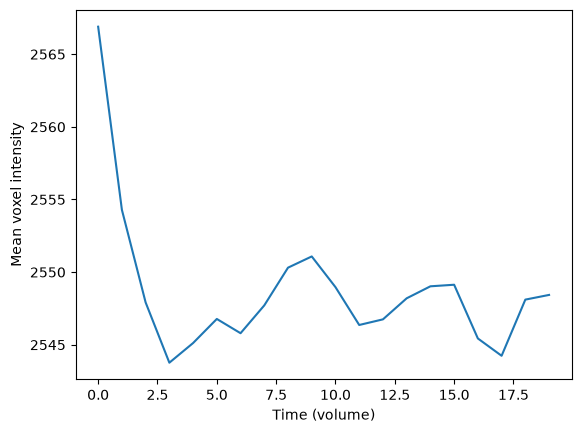

In [19]:
### View mean voxel intensity to determine volumes to remove
import matplotlib.pyplot as plt
import nibabel as nib

data = nib.load(op.join(fMRI_path, 'tfMRI_LANGUAGE_LR.nii.gz')).get_fdata().mean(axis=(0,1,2))
print("fMRI EPI Length: ", len(data))

plt.plot(data[:20])
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')

### Don't remove volumes. The mean doesn't vary that much compared to what was seen in the lab. Also the onset of the task would be displaced relative to t=0 for the fMRI images (<0). WE can also assume the data comes from newer fMRI models due to the source of the data

## Motion Correction 

In [9]:
from fsl.wrappers import mcflirt
### Define paths

path_original_data = op.join(fMRI_path, 'tfMRI_LANGUAGE_LR')
path_moco_data = op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_moco')

### Select Midline

mcflirt(infile=path_original_data,o=path_moco_data, plots=True, report=True, dof=6, mats=True)

Processed data will be saved as /neurodesktop-storage/derivatives/preprocessed_data/func/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [158] to 8 mm pixels
Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][

refnum = 158
Original_refvol = -1


Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][308][309][310][311][312][313][314][315][157][156][155][154][153][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][

{}

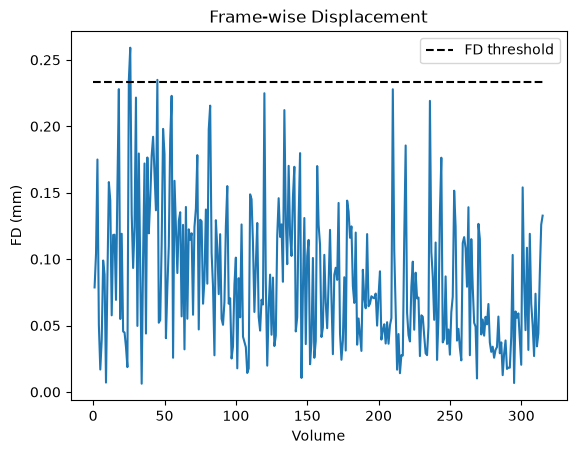

In [20]:
### Compute frame-wise displacement (FD)

def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep='  ', header=None, 
            engine='python', names=['Rotation x', 'Rotation y', 'Rotation z','Translation x', 'Translation y', 'Translation z'])

def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]

    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    # Estimating displacement on a 50mm radius sphere =: brain
    converted_rots = rot_params*50 
    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
    fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    return fd

mot_params = load_mot_params_fsl_6_dof(op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_moco.par'))
fd = compute_FD_power(mot_params).to_numpy()

### Define mcflirt used threshold

threshold = np.quantile(fd,0.75) + 1.5*(np.quantile(fd,0.75) - np.quantile(fd,0.25))

### FD Plot

plt.plot(list(range(1, fd.size+1)), fd)
plt.title("Frame-wise Displacement")
plt.xlabel('Volume')
plt.ylabel('FD (mm)')
plt.hlines(threshold, 0, len(data),colors='black', linestyles='dashed', label='FD threshold') # len(data) from mean voxel intensity test
plt.legend()

image_root = op.join(base_root, 'Images')
plt.savefig(op.join(image_root, "FD"))

plt.show()



In [ ]:
print(f"Indices of frames above threshold: {(np.where(fd > threshold)[0] + 1).tolist()}")

In [ ]:
### View Motion Corrected EPI 

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(path_original_data)
fsleyesDisplay.load(path_moco_data)

## Coregistration func to anat

In [11]:
from fsl.wrappers import epi_reg

### Define paths

epi_source = path_moco_data
whole_t1 = op.join(preproc_root, 'anat', 'T1_biascorr.nii.gz') #Use fsl_anat whole_t1 head, as it shares the same headers
skull_stripped_t1 = op.join(preproc_root, 'anat', 'T1_biascorr_brain.nii.gz')
output_path = op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_bbr')
ref_vol_name =  op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_vol_middle')
white_matter_segmentation = op.join(preproc_root, 'anat', 'T1_fast_pve_2.nii.gz')

### Extract middle volume

fslroi(epi_source, ref_vol_name, str(158), str(1))

{}

In [ ]:

### Run epi-reg using fast white matter segmentation
subprocess.run(['epi_reg','--epi={}'.format(ref_vol_name), '--t1={}'.format(whole_t1), '--t1brain={}'.format(skull_stripped_t1), 
                '--out={}'.format(output_path),
               '--wmseg={}'.format(white_matter_segmentation)])

In [ ]:
### View coregistration results
fsleyesDisplay.resetOverlays()

# Load the anatomical image registered to MNI space
mni_anat = op.join(preproc_root, 'anat', 'T1_to_MNI_nonlin.nii.gz')
fsleyesDisplay.load(mni_anat)

# Load the middle volume of the fMRI data WITHOUT epireg
fMRI_vol = ref_vol_name + '.nii.gz'
fsleyesDisplay.load(fMRI_vol)

# Set colormap / opacity to clearly view alignment between EPI and anatomical contours
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'hot'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).alpha = 60.0

In [13]:

### View alignment WITH epi_reg
fsleyesDisplay.resetOverlays()

# Load anatomical reference (MNI space)
mni_anat = op.join(preproc_root, 'anat', 'T1_to_MNI_nonlin.nii.gz')
fsleyesDisplay.load(mni_anat)

# Load the volume produced by epi_reg
fMRI_vol_with_epireg = op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_bbr.nii.gz')
fsleyesDisplay.load(fMRI_vol_with_epireg)

# Display settings: set displayRange min above 0 to make background transparent
opts = fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1])
opts.cmap = 'hot'
opts.alpha = 60.0
opts.displayRange = (150, 1000)  # Cuts off the red background box

In [12]:
### Cleanup

def cleanup_epi_reg(path_to_clean):
    patterns = ['*_fast_*', '*_fieldmap*']
    for p in patterns:
        files = glob.glob(op.join(path_to_clean, p))
        for f in files:
            os.remove(f)

cleanup_epi_reg(op.join(preproc_root, 'func'))

## Smoothing

In [15]:
### Define path
input_path = path_moco_data + '.nii.gz'
output_path = op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_moco')

### Voxel Size 

voxel_size = nib.load(input_path).header.get_zooms()[:3]
print(voxel_size)

(np.float32(2.0), np.float32(2.0), np.float32(2.0))


In [ ]:
FWHM = voxel_size[0] * 2

### Smoothing (4mm)
subprocess.run(['fslmaths', input_path, '-s', str(FWHM / 2.3548), f'{output_path}_smoothed-4mm'])

In [ ]:
### View Smoothing Result

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(input_path)
fsleyesDisplay.load(f'{output_path}_smoothed-4mm.nii.gz')

In [16]:
### Verify final preprocessed fMRI path for GLM
final_preprocessed_fmri = f'{output_path}_smoothed-4mm.nii.gz'
print("Preprocessed file:", final_preprocessed_fmri)
assert op.exists(final_preprocessed_fmri), f"Error: {final_preprocessed_fmri} not found!"

Preprocessed file: /neurodesktop-storage/derivatives/preprocessed_data/func/tfMRI_LANGUAGE_LR_moco_smoothed-4mm.nii.gz


# 3) GLM Analysis

In [22]:
import seaborn as sns
from nilearn.glm.first_level import make_first_level_design_matrix, FirstLevelModel
from nilearn.glm import threshold_stats_img
from nilearn.plotting import plot_design_matrix, plot_stat_map, plot_contrast_matrix

# Ensure Images directory exists
mkdir_no_exist(image_root)

# Path to your smoothed fMRI file and task onsets CSV
smoothed_fmri_path = op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_moco_smoothed-4mm.nii.gz')
events_csv_path = op.join(fMRI_path, 'tfMRI_LANGUAGE_LR_task_onsets.csv')

# Load and inspect the events CSV
events_df = pd.read_csv(events_csv_path)
print("Columns in CSV:", events_df.columns.tolist())
print("\nUnique trial_type values:\n", events_df['trial_type'].value_counts())
events_df.head(10)

Columns in CSV: ['onset', 'duration', 'trial_type']

Unique trial_type values:
 trial_type
present_math      9
math              9
question_math     9
response_math     9
cue               7
story             4
present_story     4
question_story    4
response_story    4
Name: count, dtype: int64


,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


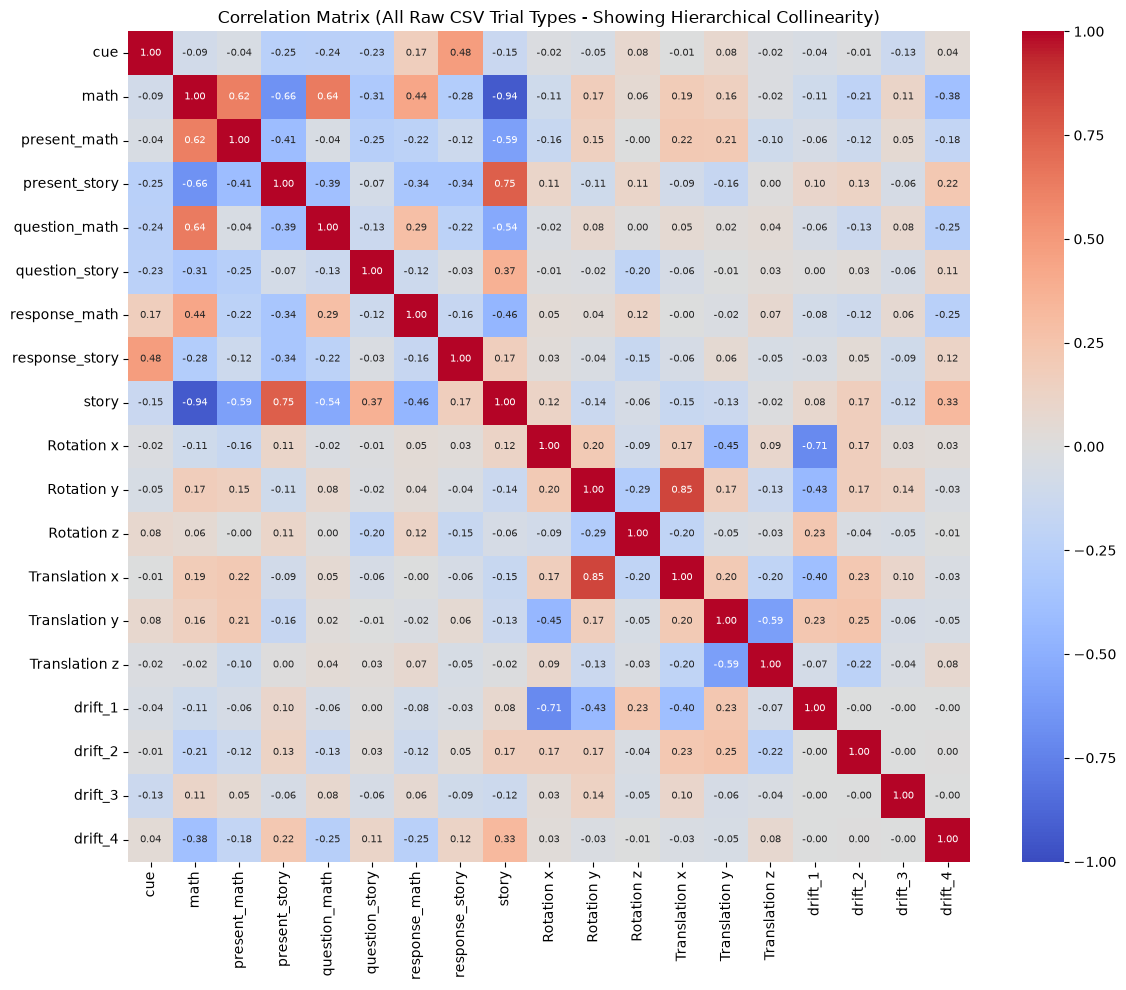

In [23]:
### 3a & 3b) Inspect Full Events vs. Clean Non-Overlapping Design Matrix

tr = float(header.get_zooms()[3])
n_scans = len(data)
frame_times = np.arange(n_scans) * tr

# 1. First, build a matrix with ALL CSV trial types to inspect collinearity
dm_all = make_first_level_design_matrix(
    frame_times=frame_times,
    events=events_df[['onset', 'duration', 'trial_type']],
    hrf_model='glover',
    drift_model='cosine',
    high_pass=0.01,
    add_regs=mot_params.values,
    add_reg_names=mot_params.columns.tolist()
)

plt.figure(figsize=(12, 10))
sns.heatmap(
    dm_all.drop(columns=['constant'], errors='ignore').corr(),
    annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, annot_kws={"size": 7}
)
plt.title("Correlation Matrix (All Raw CSV Trial Types - Showing Hierarchical Collinearity)")
plt.tight_layout()
plt.savefig(op.join(image_root, "GLM_correlation_matrix_all_events.png"), dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

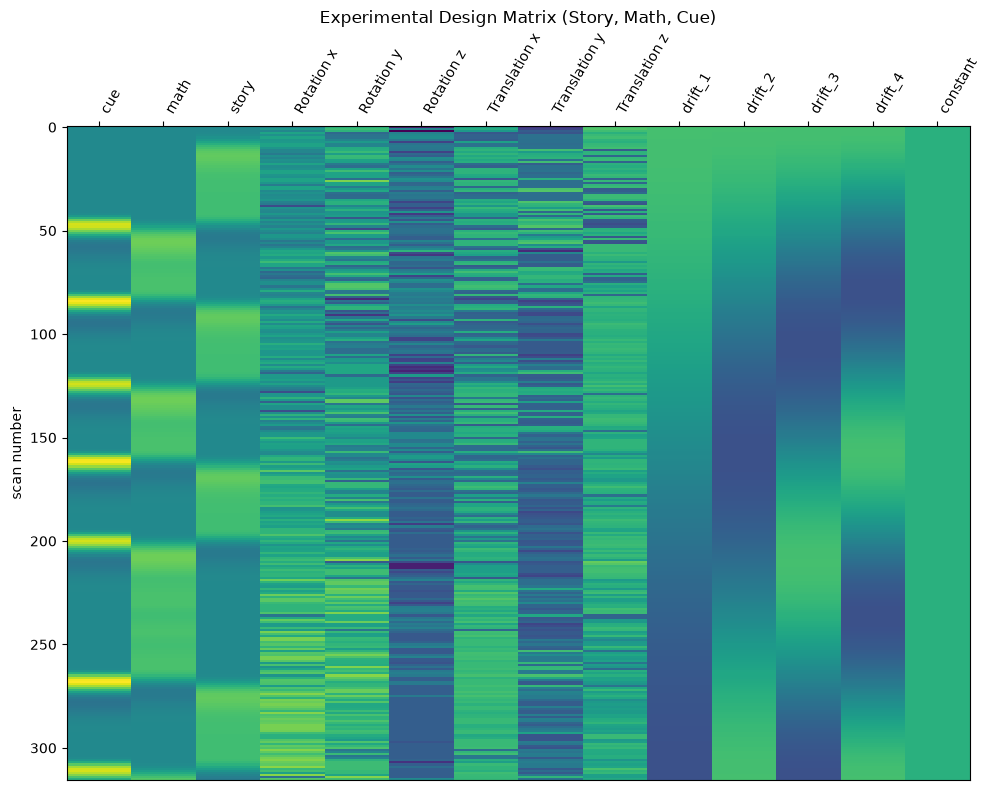

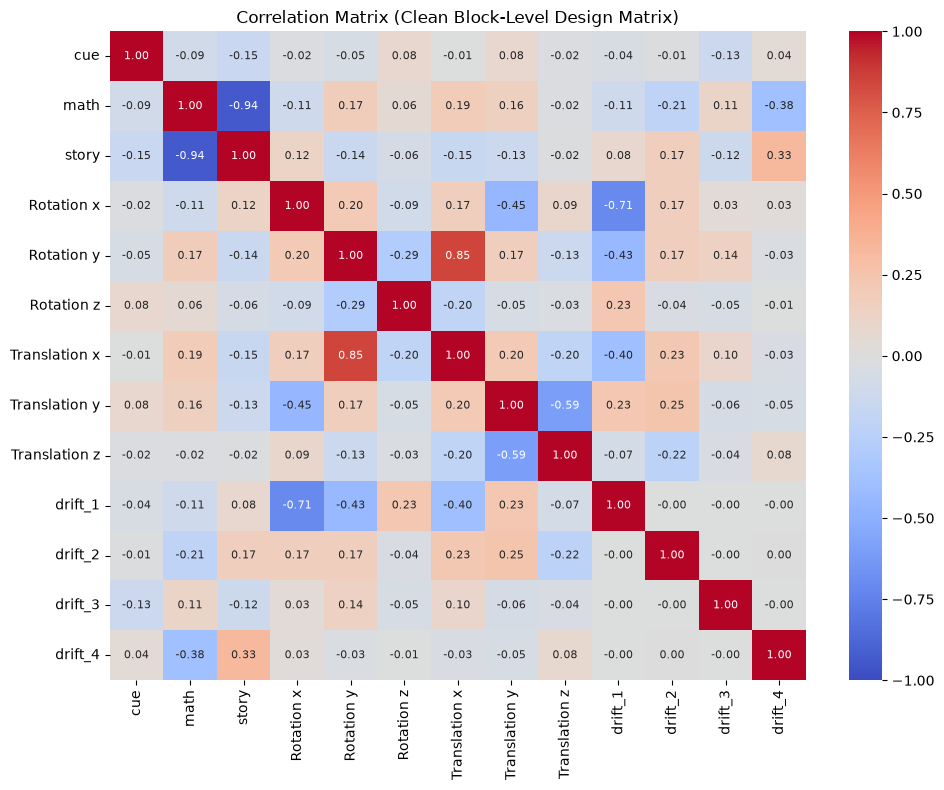

In [27]:
### Build Clean Design Matrix (Block-Level: story, math, cue) & Fit GLM (3c)

# Filter to non-overlapping block events to avoid multicollinearity with sub-events
events_clean = events_df[events_df['trial_type'].isin(['story', 'math', 'cue'])][['onset', 'duration', 'trial_type']].copy()

design_matrix = make_first_level_design_matrix(
    frame_times=frame_times,
    events=events_clean,
    hrf_model='glover',
    drift_model='cosine',
    high_pass=0.01,
    add_regs=mot_params.values,
    add_reg_names=mot_params.columns.tolist()
)
# Plot Clean Design Matrix (3a)
fig, ax = plt.subplots(figsize=(10, 8))
plot_design_matrix(design_matrix, ax=ax)
ax.set_title("Experimental Design Matrix (Story, Math, Cue)")
plt.tight_layout()
plt.savefig(op.join(image_root, "GLM_design_matrix.png"), dpi=300)
plt.show()

# Plot Clean Correlation Matrix (3b)
plt.figure(figsize=(10, 8))
sns.heatmap(
    design_matrix.drop(columns=['constant'], errors='ignore').corr(),
    annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, annot_kws={"size": 8}
)
plt.title("Correlation Matrix (Clean Block-Level Design Matrix)")
plt.tight_layout()
plt.savefig(op.join(image_root, "GLM_correlation_matrix_clean.png"), dpi=300)
plt.show()

Regressor 'story' | FDR (p<0.05) Z-threshold = 3.57


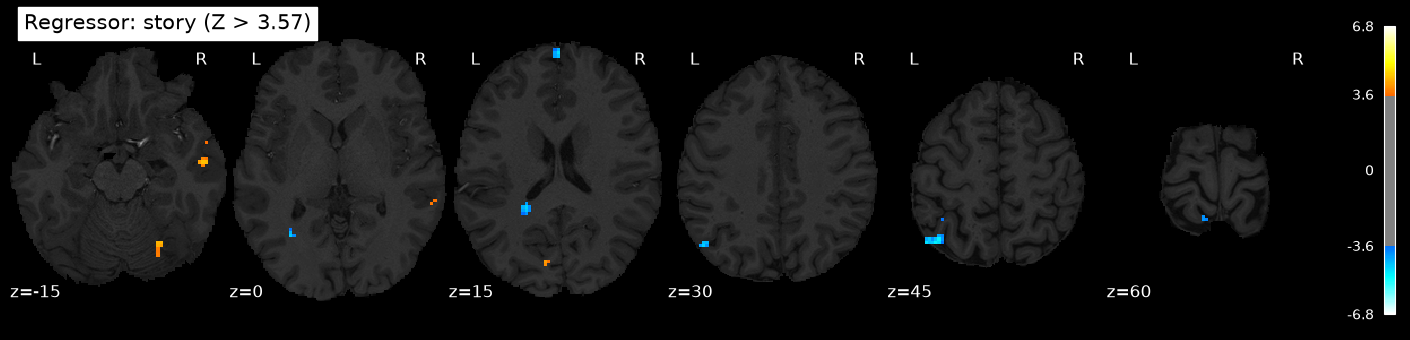

Regressor 'math' | FDR (p<0.05) Z-threshold = 3.69


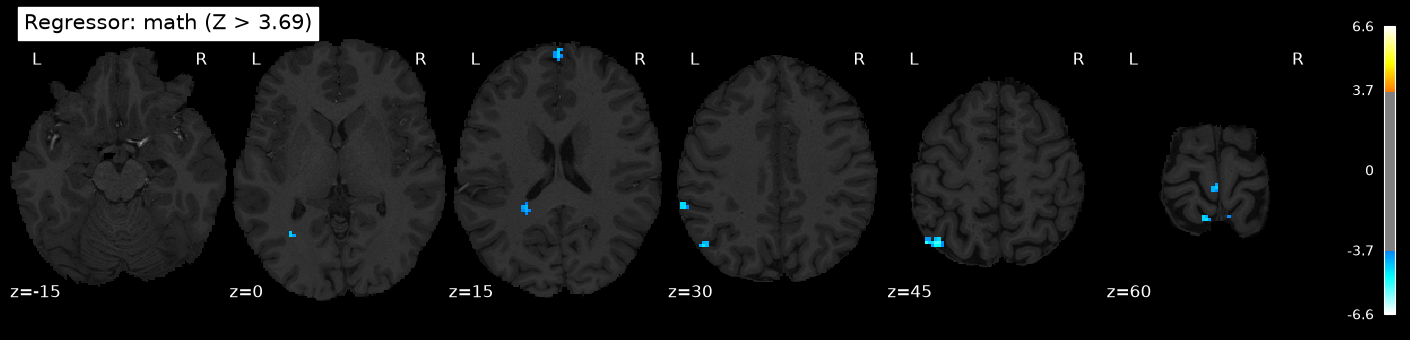

Regressor 'cue' | FDR (p<0.05) Z-threshold = 3.90


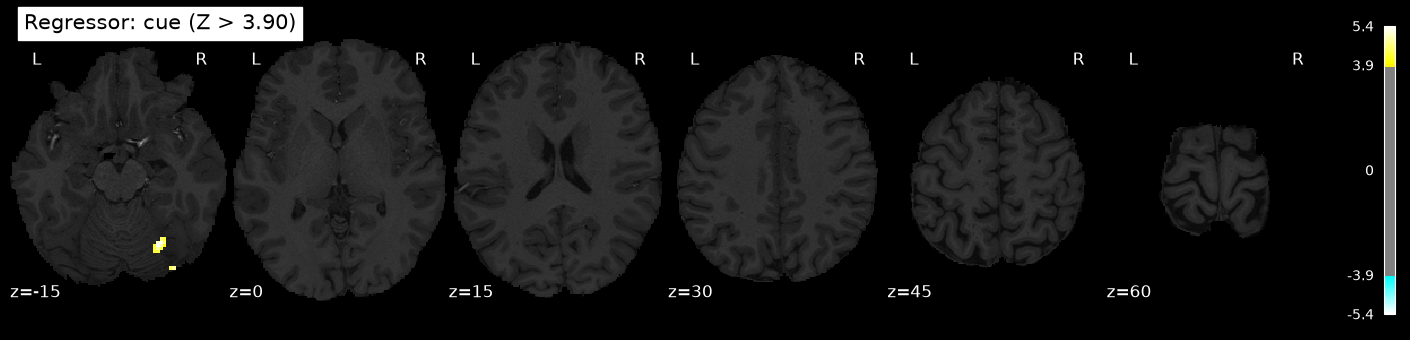

In [29]:
### 3c) Fit the First-Level GLM (with Brain Mask) and Plot Task Regressors
from nilearn.image import resample_to_img

# Resample anatomical brain mask to fMRI space to eliminate out-of-brain air voxels
func_mask = resample_to_img(
    op.join(preproc_root, 'anat', 'T1_biascorr_brain_mask.nii.gz'),
    smoothed_fmri_path,
    interpolation='nearest'
)

fmri_glm = FirstLevelModel(
    t_r=tr,
    noise_model='ar1',
    standardize=False,
    hrf_model='glover',
    drift_model='cosine',
    high_pass=0.01,
    mask_img=func_mask,
    smoothing_fwhm=None,
    minimize_memory=False
)

fmri_glm = fmri_glm.fit(smoothed_fmri_path, design_matrices=design_matrix)

# Plot statistical maps for each task regressor ('story', 'math', 'cue')
for reg in ['story', 'math', 'cue']:
    z_map = fmri_glm.compute_contrast(reg, output_type='z_score')
    clean_map, thresh = threshold_stats_img(
        z_map, alpha=0.05, height_control='fdr', cluster_threshold=10
    )
    print(f"Regressor '{reg}' | FDR (p<0.05) Z-threshold = {thresh:.2f}")
    
    if np.isinf(thresh):
        clean_map, thresh = threshold_stats_img(
            z_map, alpha=0.001, height_control='fpr', cluster_threshold=10
        )
        print(f"  -> Using uncorrected p<0.001 threshold Z = {thresh:.2f}")

    plot_stat_map(
        clean_map,
        bg_img=skull_stripped_t1,
        threshold=thresh,
        display_mode='z',
        cut_coords=[-15, 0, 15, 30, 45, 60],
        black_bg=True,
        title=f"Regressor: {reg} (Z > {thresh:.2f})"
    )
    plt.savefig(op.join(image_root, f"GLM_map_{reg}.png"), dpi=300)
    plt.show()

Design matrix columns: ['cue', 'math', 'story', 'Rotation x', 'Rotation y', 'Rotation z', 'Translation x', 'Translation y', 'Translation z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']
Contrast Vector (Story - Math): [ 0. -1.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]


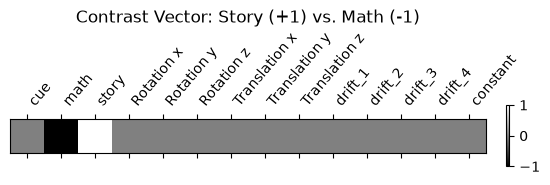

Story vs. Math | FDR (p<0.05) Z-threshold = 2.64


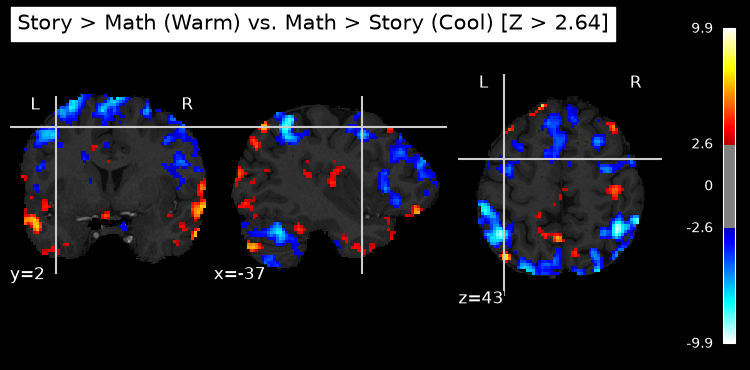

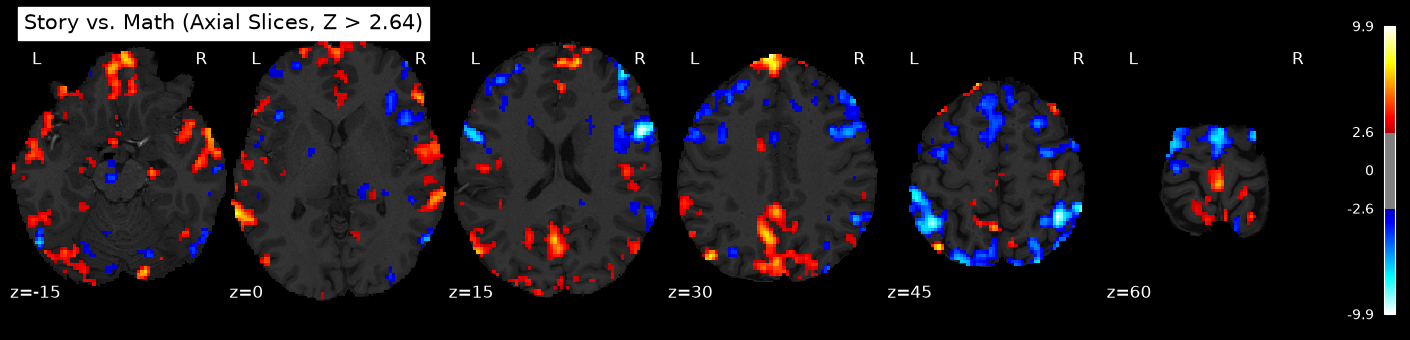

In [30]:
### 3d) Story vs. Math Contrast

contrast_vec = np.zeros(design_matrix.shape[1])
contrast_vec[design_matrix.columns.get_loc('story')] = 1.0
contrast_vec[design_matrix.columns.get_loc('math')] = -1.0

print("Design matrix columns:", list(design_matrix.columns))
print("Contrast Vector (Story - Math):", contrast_vec)

# Plot the contrast vector
plot_contrast_matrix(contrast_vec, design_matrix=design_matrix, colorbar=True)
plt.title("Contrast Vector: Story (+1) vs. Math (-1)")
plt.tight_layout()
plt.savefig(op.join(image_root, "GLM_contrast_vector.png"), dpi=300)
plt.show()

# Compute and threshold the Story vs. Math Z-score map
z_map_story_vs_math = fmri_glm.compute_contrast(contrast_vec, output_type='z_score')
clean_contrast, thresh_c = threshold_stats_img(
    z_map_story_vs_math, alpha=0.05, height_control='fdr', cluster_threshold=15
)
print(f"Story vs. Math | FDR (p<0.05) Z-threshold = {thresh_c:.2f}")

# Plot Orthogonal view
plot_stat_map(
    clean_contrast,
    bg_img=skull_stripped_t1,
    threshold=thresh_c,
    display_mode='ortho',
    black_bg=True,
    title=f"Story > Math (Warm) vs. Math > Story (Cool) [Z > {thresh_c:.2f}]"
)
plt.savefig(op.join(image_root, "GLM_contrast_story_vs_math_ortho.png"), dpi=300)
plt.show()

# Plot Axial view across slices
plot_stat_map(
    clean_contrast,
    bg_img=skull_stripped_t1,
    threshold=thresh_c,
    display_mode='z',
    cut_coords=[-15, 0, 15, 30, 45, 60],
    black_bg=True,
    title=f"Story vs. Math (Axial Slices, Z > {thresh_c:.2f})"
)
plt.savefig(op.join(image_root, "GLM_contrast_story_vs_math_axial.png"), dpi=300)
plt.show()

In [33]:
### 3e) Local Harvard-Oxford Atlas Check
import xml.etree.ElementTree as ET

ho_atlas_path = op.expandvars('$FSLDIR/data/atlases/HarvardOxford/HarvardOxford-cort-maxprob-thr25-2mm.nii.gz')
ho_xml_path = op.expandvars('$FSLDIR/data/atlases/HarvardOxford-Cortical.xml')

# Parse labels from the XML file
tree = ET.parse(ho_xml_path)
labels = {int(l.attrib['index']): l.text for l in tree.findall('.//label')}

# Resample atlas to match your GLM contrast map
from nilearn.image import resample_to_img
ho_resampled = resample_to_img(ho_atlas_path, clean_contrast, interpolation='nearest')
ho_data = np.squeeze(ho_resampled.get_fdata()).astype(int)
z_data = clean_contrast.get_fdata()

records = []
for idx, name in labels.items():
    mask = (ho_data == (idx + 1))  # maxprob thr labels are 1-indexed
    n_story = int(np.sum((z_data > thresh_c) & mask))
    n_math = int(np.sum((z_data < -thresh_c) & mask))
    if n_story > 0 or n_math > 0:
        records.append({"Structure": name, "Story > Math (voxels)": n_story, "Math > Story (voxels)": n_math})

df_regions = pd.DataFrame(records).sort_values(by="Story > Math (voxels)", ascending=False)
display(df_regions.head(15))

,Structure,Story > Math (voxels),Math > Story (voxels)
30,Precuneous Cortex,997,519
0,Frontal Pole,839,747
7,Temporal Pole,744,0
29,"Cingulate Gyrus, posterior division",614,1
21,"Lateral Occipital Cortex, superior division",501,586
27,Paracingulate Gyrus,434,355
6,Precentral Gyrus,423,972
9,"Superior Temporal Gyrus, posterior division",414,16
31,Cuneal Cortex,360,0
24,Frontal Medial Cortex,357,0
